# 🛞 TireGuard — Tire Quality Classification

**Project:** Tire Quality Classification using Convolutional Neural Networks (CNN)

**Dataset:** [Tyre Quality Classification — Kaggle](https://www.kaggle.com/datasets/warcoder/tyre-quality-classification)

**Objective:** Build a CNN model to classify tyre images into two classes: Defective and Good.

**Framework:** TensorFlow / Keras

In [ ]:
!pip install -q kagglehub

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "warcoder/tyre-quality-classification"
)

data_dir = os.path.join(
    path,
    "Digital images of defective and good condition tyres"
)

print(os.listdir(data_dir))

Using Colab cache for faster access to the 'tyre-quality-classification' dataset.
['good', 'defective']


In [ ]:
class_names = ["good", "defective"]

for name in class_names:
    folder = os.path.join(data_dir, name)
    print(name, len(os.listdir(folder)))

good 828
defective 1028


In [ ]:
image_paths = []
labels = []

for label, class_name in enumerate(class_names):
    folder = os.path.join(data_dir, class_name)

    for filename in os.listdir(folder):
        file_path = os.path.join(folder, filename)

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(file_path)
            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

print("Total images:", len(image_paths))
print("Labels shape:", labels.shape)

Total images: 1856
Labels shape: (1856,)


In [ ]:
for file_path in image_paths[:5]:
    with Image.open(file_path) as img:
        print(img.size, img.mode)

(1800, 4000) RGB
(1800, 4000) RGB
(4000, 1800) RGB
(4000, 1800) RGB
(1800, 4000) RGB


In [ ]:
IMG_SIZE = (224, 224)

def preprocess_image(file_path):
    img = Image.open(file_path).convert("RGB")
    img = img.resize(IMG_SIZE)

    img = np.array(img, dtype=np.float32) / 255.0

    return img

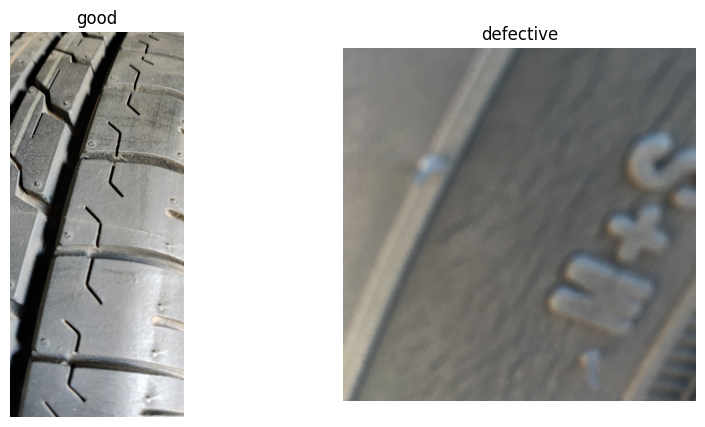

In [ ]:
plt.figure(figsize=(10, 5))

for i, class_name in enumerate(class_names):
    idx = np.where(labels == i)[0][0]
    img = Image.open(image_paths[idx]).convert("RGB")

    plt.subplot(1, 2, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.show()

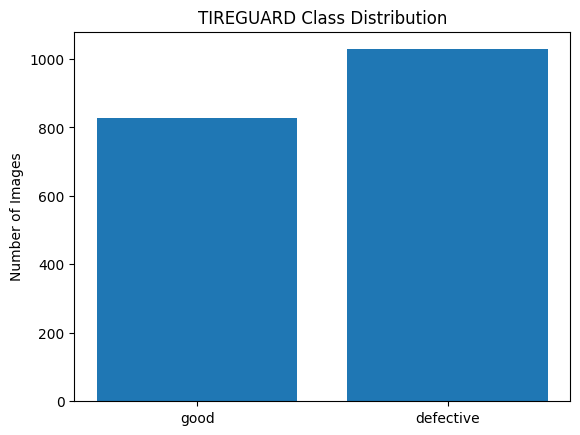

{'good': np.int64(828), 'defective': np.int64(1028)}


In [ ]:
counts = [np.sum(labels == i) for i in range(len(class_names))]

plt.bar(class_names, counts)
plt.title("TIREGUARD Class Distribution")
plt.ylabel("Number of Images")
plt.show()

print(dict(zip(class_names, counts)))

In [ ]:
!pip install split-folders

In [ ]:
import splitfolders

In [ ]:
import splitfolders
import os

splitfolders.ratio(
    data_dir,
    output="/content/TIREGUARD",
    seed=42,
    ratio=(0.8, 0.1, 0.1)
)

Copying files: 1856 files [00:48, 38.07 files/s]


In [ ]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 64

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/TIREGUARD/train",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/TIREGUARD/test",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/TIREGUARD/val",
    seed=123,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE
)

Found 1484 files belonging to 2 classes.
Found 188 files belonging to 2 classes.
Found 184 files belonging to 2 classes.


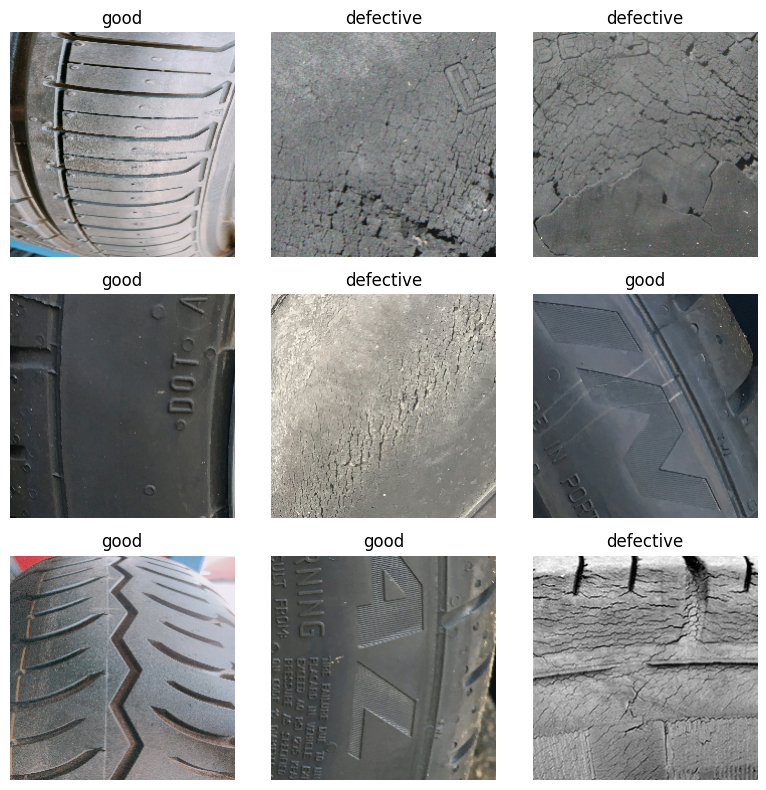

In [ ]:
import matplotlib.pyplot as plt

class_names = train_ds.class_names

plt.figure(figsize=(8, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

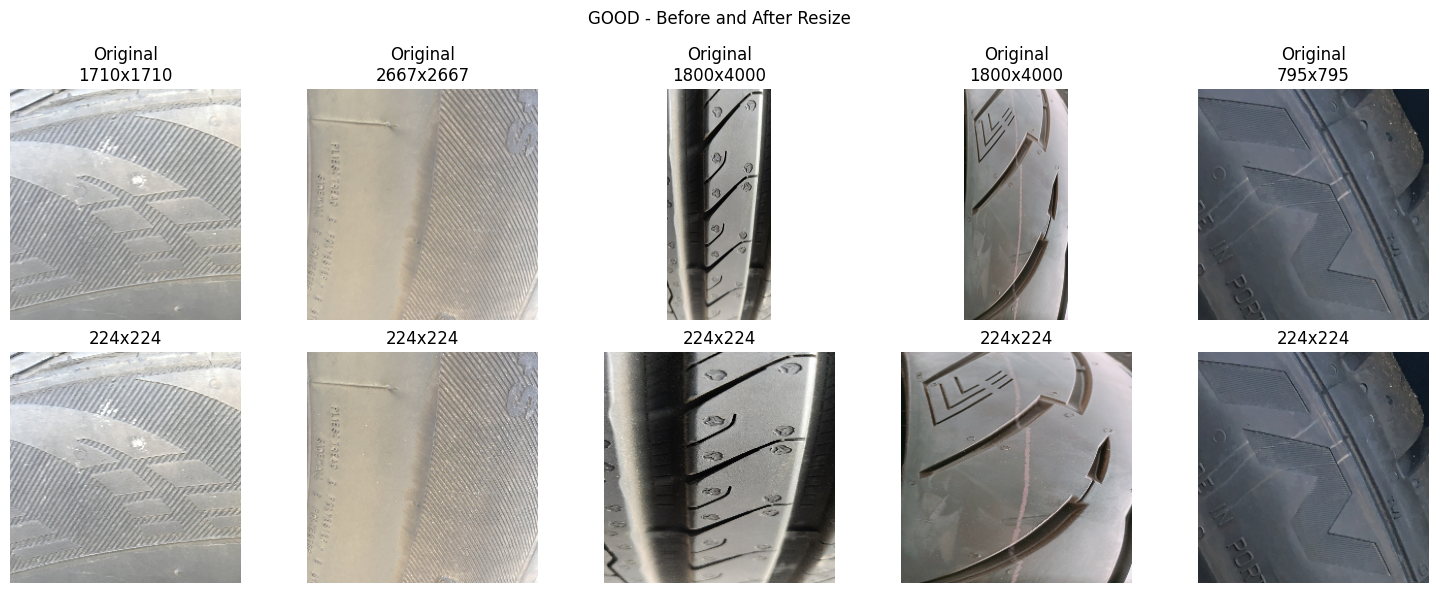

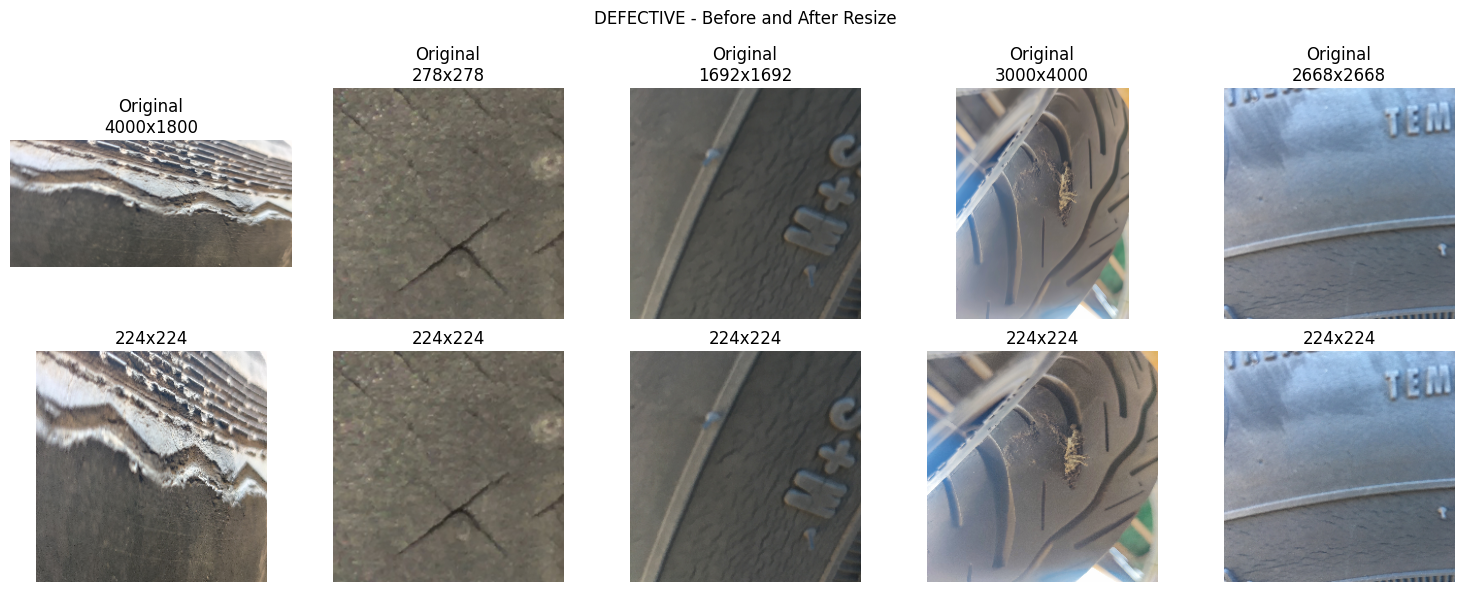

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

categories = ["good", "defective"]

for category in categories:
    folder = os.path.join("/content/TIREGUARD/train", category)
    image_names = os.listdir(folder)[:5]

    plt.figure(figsize=(15, 6))
    plt.suptitle(f"{category.upper()} - Before and After Resize")

    for i, image_name in enumerate(image_names):
        image_path = os.path.join(folder, image_name)

        img = cv2.imread(image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img, (224, 224))

        # Before
        plt.subplot(2, 5, i + 1)
        plt.imshow(img)
        plt.title(f"Original\n{img.shape[1]}x{img.shape[0]}")
        plt.axis("off")

        # After
        plt.subplot(2, 5, i + 6)
        plt.imshow(img_resized)
        plt.title("224x224")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
print("Class names:", train_ds.class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Class names: ['defective', 'good']
Training batches: 24
Validation batches: 3
Testing batches: 3


In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Rescaling, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.metrics import Precision, Recall

# Build Model1 - Custom CNN
Model1 = Sequential([
    Input(shape=(224, 224, 3)),

    Rescaling(1./255),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

Model1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        Precision(name="precision"),
        Recall(name="recall")
    ]
)

Model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history1 = Model1.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds,
    verbose=1
)

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 85s 3s/step - accuracy: 0.5532 - loss: 0.6831 - precision: 0.4545 - recall: 0.0076 - val_accuracy: 0.5598 - val_loss: 0.6761 - val_precision: 1.0000 - val_recall: 0.0122
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 138s 3s/step - accuracy: 0.6058 - loss: 0.6633 - precision: 0.6571 - recall: 0.2432 - val_accuracy: 0.6630 - val_loss: 0.6457 - val_precision: 0.5962 - val_recall: 0.7561
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 82s 3s/step - accuracy: 0.6597 - loss: 0.6290 - precision: 0.6536 - recall: 0.5045 - val_accuracy: 0.6848 - val_loss: 0.6180 - val_precision: 0.7308 - val_recall: 0.4634
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 85s 3s/step - accuracy: 0.6705 - loss: 0.6139 - precision: 0.6629 - recall: 0.5317 - val_accuracy: 0.6848 - val_loss: 0.6163 - val_precision: 0.7400 - val_recall: 0.4512
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 90s 4s/step - accuracy: 0.6840 - loss: 0.6118 - precision: 0.6784 - recall: 0.5544 - val_accuracy: 0.7228 - val_loss: 0.6062 - va

In [ ]:
results1 = Model1.evaluate(test_ds, verbose=1, return_dict=True)

print(f"Test Accuracy:  {results1['accuracy']:.4f}")
print(f"Test Precision: {results1['precision']:.4f}")
print(f"Test Recall:    {results1['recall']:.4f}")
print(f"Test Loss:      {results1['loss']:.4f}")

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Rescaling, GlobalAveragePooling2D,
    Dense, Dropout
)
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.metrics import Precision, Recall

# Pretrained MobileNetV1
base_model = MobileNet(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

model = Sequential([
    Input(shape=(224, 224, 3)),

    # MobileNetV1 preprocessing: [0,255] -> [-1,1]
    Rescaling(1./127.5, offset=-1),

    base_model,

    GlobalAveragePooling2D(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(24, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        Precision(name="precision"),
        Recall(name="recall")
    ]
)

model.summary()

In [ ]:
history = model.fit(
    train_ds,
    epochs=15,
    validation_data=val_ds,
    batch_size=32,
    verbose=1
)

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.7426 - loss: 0.5160 - precision: 0.7194 - recall: 0.6934 - val_accuracy: 0.8370 - val_loss: 0.3224 - val_precision: 0.8611 - val_recall: 0.7561
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.8841 - loss: 0.2783 - precision: 0.8668 - recall: 0.8746 - val_accuracy: 0.9022 - val_loss: 0.2446 - val_precision: 0.8556 - val_recall: 0.9390
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.9292 - loss: 0.1977 - precision: 0.9252 - recall: 0.9154 - val_accuracy: 0.9022 - val_loss: 0.2232 - val_precision: 0.8478 - val_recall: 0.9512
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 114s 3s/step - accuracy: 0.9400 - loss: 0.1697 - precision: 0.9207 - recall: 0.9471 - val_accuracy: 0.9239 - val_loss: 0.1782 - val_precision: 0.9048 - val_recall: 0.9268
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 86s 4s/step - accuracy: 0.9508 - loss: 0.1414 - precision: 0.9482 - recall: 0.9411 - val_accuracy: 0.9022 - val_loss: 0.1857 - va

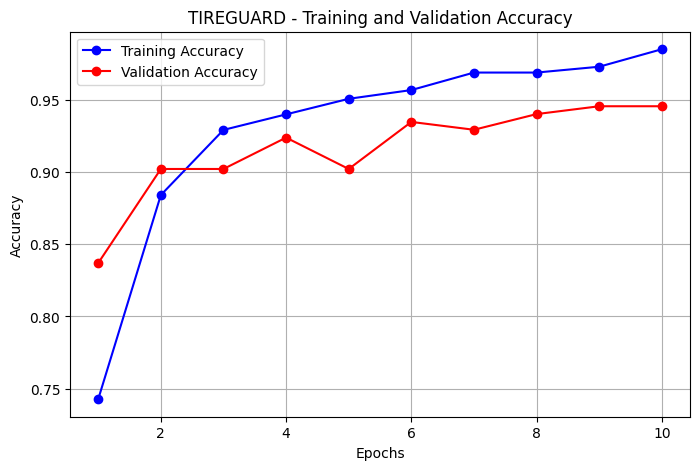

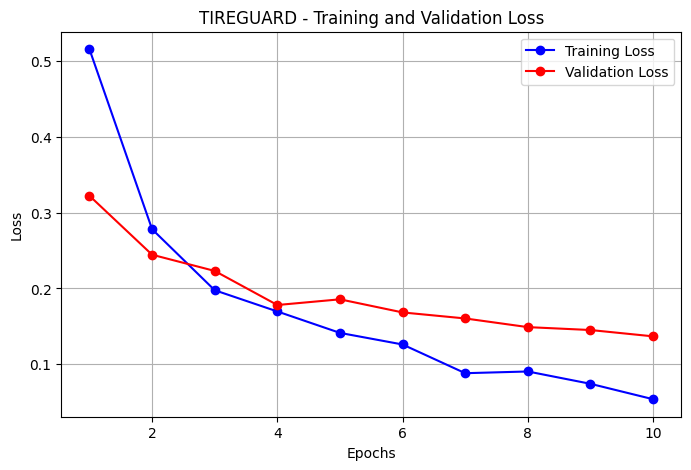

In [ ]:

import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# Training and Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, acc, 'b-o', label='Training Accuracy')
plt.plot(epochs, val_acc, 'r-o', label='Validation Accuracy')
plt.title('TIREGUARD - Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Training and Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, loss, 'b-o', label='Training Loss')
plt.plot(epochs, val_loss, 'r-o', label='Validation Loss')
plt.title('TIREGUARD - Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


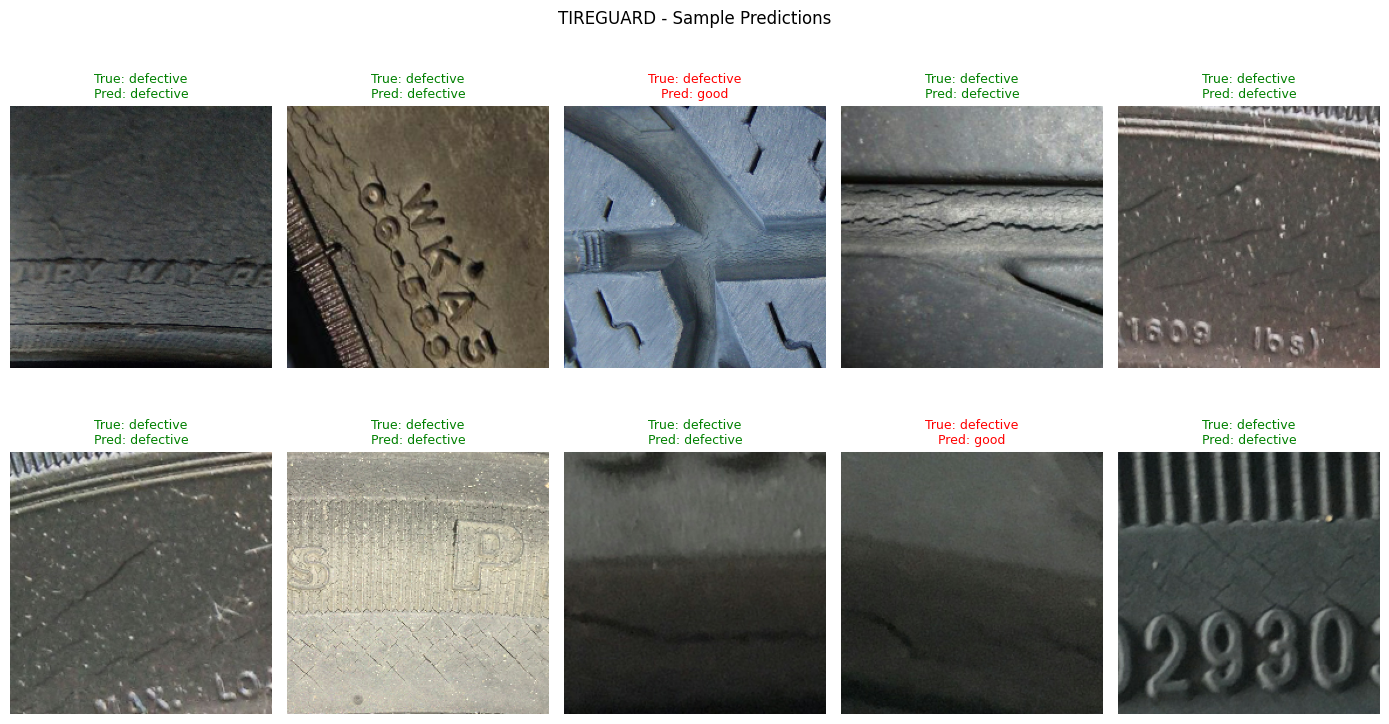

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Sample predictions
class_names = test_ds.class_names

images, labels = next(iter(test_ds.take(1)))
predictions = model.predict(images, verbose=0)

preds = (predictions.flatten() >= 0.5).astype(int)
labels = labels.numpy()

plt.figure(figsize=(14, 8))

for i in range(min(10, len(images))):
    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].numpy().astype("uint8"))

    true_label = class_names[labels[i]]
    pred_label = class_names[preds[i]]

    color = "green" if preds[i] == labels[i] else "red"

    plt.title(
        f"True: {true_label}\nPred: {pred_label}",
        color=color,
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("TIREGUARD - Sample Predictions")
plt.tight_layout()
plt.savefig("TIREGUARD_predictions.png", dpi=150)
plt.show()


Predicted: good
True: defective


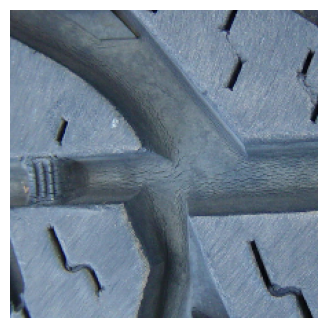

Predicted: good
True: defective


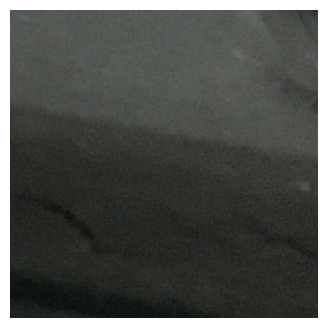

Predicted: good
True: defective


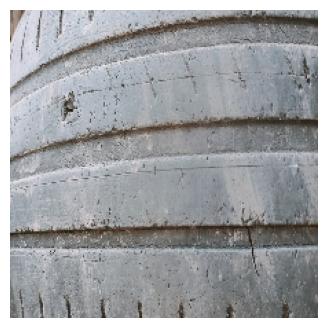

Predicted: good
True: defective


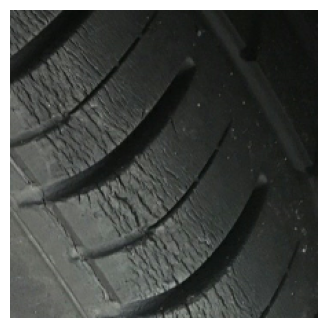

Predicted: defective
True: good


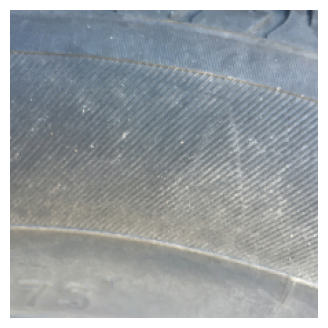

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Get true labels and predictions
Y_true = np.concatenate([labels.numpy() for images, labels in test_ds])

predictions = model.predict(test_ds, verbose=0).flatten()
Y_pred_classes = (predictions >= 0.5).astype(int)

# Get the errors
errors = Y_pred_classes != Y_true

X_test = np.concatenate([images.numpy() for images, labels in test_ds])

X_test_errors = X_test[errors]
Y_pred_classes_errors = Y_pred_classes[errors]
Y_true_errors = Y_true[errors]

# Class names
class_names = test_ds.class_names

# Show first 5 errors
for i in range(min(5, len(X_test_errors))):
    plt.figure(figsize=(4, 4))

    plt.imshow(X_test_errors[i].astype("uint8"))

    print("Predicted:", class_names[Y_pred_classes_errors[i]])
    print("True:", class_names[Y_true_errors[i]])

    plt.axis("off")
    plt.show()

if len(X_test_errors) == 0:
    print("No misclassified images found!")


In [ ]:
# Evaluate the model
results = model.evaluate(test_ds, verbose=1)

print(f"Test Loss      : {results[0]:.4f}")
print(f"Test Accuracy  : {results[1]*100:.2f}%")
print(f"Test Precision : {results[2]*100:.2f}%")
print(f"Test Recall    : {results[3]*100:.2f}%")


3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 5s/step - accuracy: 0.9574 - loss: 0.1325 - precision: 0.9524 - recall: 0.9524
Test Loss      : 0.1325
Test Accuracy  : 95.74%
Test Precision : 95.24%
Test Recall    : 95.24%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

y_test_int = []
y_pred_test_int = []
y_pred_prob = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0).ravel()

    y_test_int.extend(labels.numpy().astype(int))
    y_pred_prob.extend(predictions)
    y_pred_test_int.extend((predictions >= 0.5).astype(int))

y_test_int = np.array(y_test_int)
y_pred_test_int = np.array(y_pred_test_int)
y_pred_prob = np.array(y_pred_prob)

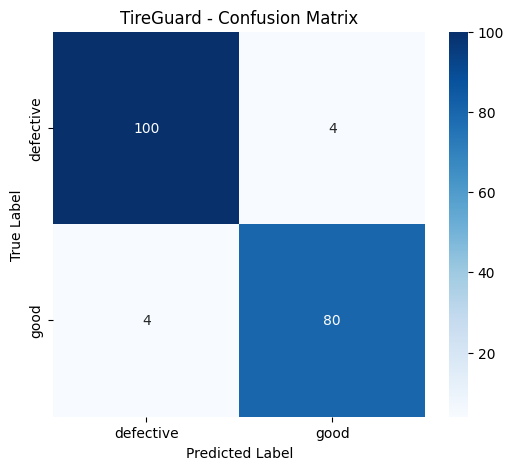

In [ ]:
cm = confusion_matrix(y_test_int, y_pred_test_int)

plt.figure(figsize=(6, 5))
sn.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["defective", "good"],
    yticklabels=["defective", "good"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("TireGuard - Confusion Matrix")
plt.show()

In [ ]:
target_names = ["defective", "good"]

print(classification_report(
    y_test_int,
    y_pred_test_int,
    target_names=target_names,
    digits=4
))

              precision    recall  f1-score   support

   defective     0.9615    0.9615    0.9615       104
        good     0.9524    0.9524    0.9524        84

    accuracy                         0.9574       188
   macro avg     0.9570    0.9570    0.9570       188
weighted avg     0.9574    0.9574    0.9574       188



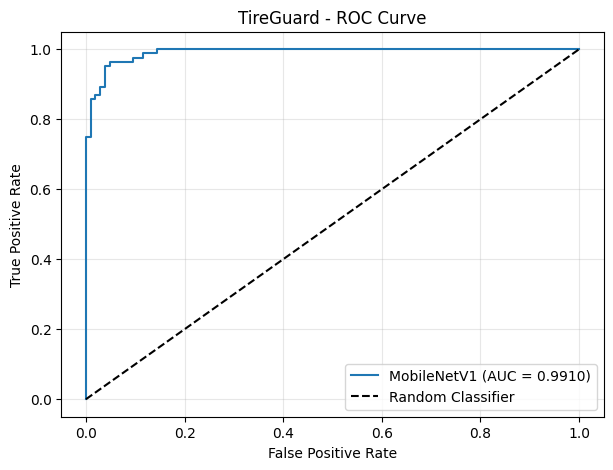

ROC-AUC Score: 0.9910


In [ ]:
fpr, tpr, thresholds = roc_curve(y_test_int, y_pred_prob)
auc_score = roc_auc_score(y_test_int, y_pred_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"MobileNetV1 (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("TireGuard - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"ROC-AUC Score: {auc_score:.4f}")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

model.save('/content/drive/MyDrive/TIREGUARD___MobileNet_best.keras')

print("Model saved successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved successfully!
